# Model selection: the scorer decides, and so does how you average the folds

Two choices that look like details decide which model you ship and what number you report:

1. the **scoring function** `GridSearchCV` maximises: accuracy, macro-$F_1$ or macro-recall can pick
   different models on imbalanced data;
2. the way the **folds are combined**: the mean of per-fold scores (what `cross_val_score` returns) is
   not the score of the pooled predictions, and for some measures the difference is large.

The notebook ends with a test that fails when an evaluation is flawed.

In [1]:
# Installs the package only where it is missing (for example in Colab).
import importlib.util
if importlib.util.find_spec("aggmetrics") is None:
    %pip install -q aggmetrics scikit-learn matplotlib pandas

In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split

from aggmetrics import IndicatorMatrix, diagnose, fold_aggregate, make_scorer, pareto_dominance

BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.edgecolor": INK2, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "lines.linewidth": 2, "font.size": 10, "figure.dpi": 100,
})

## An imbalanced problem

The imbalanced `digits` profile of notebook 02: from 170 examples of class 0 down to 5 of class 9. A
stratified split keeps 60% for training and holds out 40% as a test set.

In [3]:
X, y = load_digits(return_X_y=True)
keep = {0: 170, 1: 120, 2: 85, 3: 60, 4: 42, 5: 30, 6: 20, 7: 14, 8: 9, 9: 5}
rng = np.random.default_rng(0)
idx = np.concatenate([rng.choice(np.flatnonzero(y == c), k, replace=False) for c, k in keep.items()])
X, y = X[idx] / 16.0, y[idx]
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.4, stratify=y, random_state=0)
print("test examples per class:", np.bincount(yte))

test examples per class: [68 48 34 24 17 12  8  6  3  2]


## The scorer picks the model

`GridSearchCV` searches over the regularisation `C` and over `class_weight`, scored three ways. The
two `aggmetrics` scorers come from `make_scorer`, with the same operator names used everywhere else.

In [4]:
cv = StratifiedKFold(3, shuffle=True, random_state=0)
grid = {"C": [0.01, 0.03, 0.1, 0.3, 1, 3], "class_weight": [None, "balanced"]}
scorers = {
    "accuracy": "accuracy",
    "macro-F1": make_scorer("f1", "macro", task="multiclass"),
    "macro-recall": make_scorer("recall", "macro", task="multiclass"),
}

searches, rows = {}, []
for name, scoring in scorers.items():
    gs = GridSearchCV(LogisticRegression(max_iter=3000), grid, scoring=scoring, cv=cv).fit(Xtr, ytr)
    searches[name] = gs
    im_te = IndicatorMatrix(yte, gs.predict(Xte), task="multiclass", n_classes=10)
    rows.append(dict(scorer=name, C=gs.best_params_["C"], class_weight=gs.best_params_["class_weight"],
                     cv_score=gs.best_score_, test_accuracy=im_te.accuracy(),
                     test_macro_F1=im_te.compute("f1", "macro"),
                     test_macro_recall=im_te.compute("recall", "macro")))
pd.DataFrame(rows).set_index("scorer").round(3)

,C,class_weight,cv_score,test_accuracy,test_macro_F1,test_macro_recall
scorer,,,,,,
accuracy,3,None,0.952,0.964,0.882,0.861
macro-F1,3,None,0.817,0.964,0.882,0.861
macro-recall,1,balanced,0.822,0.968,0.920,0.950


Accuracy and macro-$F_1$ choose `C=3` without class weights. Macro-recall chooses `C=1` with
`class_weight="balanced"`, and that model is better on the held-out test set on all three measures. The
test set is small, with 3 and 2 examples in the two rarest classes, so read the difference as an
illustration of the mechanism, not as a ranking of the two settings. What the per-class recall shows is
where it comes from:

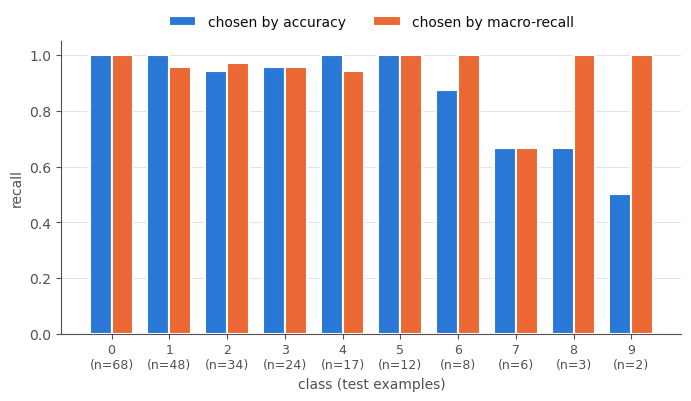

In [5]:
a = IndicatorMatrix(yte, searches["accuracy"].predict(Xte), task="multiclass", n_classes=10)
b = IndicatorMatrix(yte, searches["macro-recall"].predict(Xte), task="multiclass", n_classes=10)
support = np.bincount(yte)

fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.arange(10)
w = 0.38
ax.bar(x - w / 2, a.parts("recall", "macro"), w, color=BLUE, edgecolor="white", linewidth=1.5,
       label="chosen by accuracy")
ax.bar(x + w / 2, b.parts("recall", "macro"), w, color=ORANGE, edgecolor="white", linewidth=1.5,
       label="chosen by macro-recall")
ax.set_xticks(x)
ax.set_xticklabels([f"{c}\n(n={n})" for c, n in zip(x, support)], fontsize=9)
ax.set_xlabel("class (test examples)")
ax.set_ylabel("recall")
ax.set_ylim(0, 1.05)
ax.grid(axis="x", visible=False)
ax.legend(frameon=False, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2)
plt.show()

The accuracy-chosen model loses on the two rarest classes (8 and 9), which hardly move its accuracy. The
other is slightly worse on classes 1 and 4. So neither dominates the other:

In [6]:
pareto_dominance(a, b)

'incomparable'

`'incomparable'` means no choice of measure that rewards correct predictions and penalises errors can
rank them without a trade-off between classes. Deciding which classes matter is a decision about the
application, and it is what the scorer encodes.

## The number you report: pooled or averaged

`cross_val_score` and `GridSearchCV` report the **mean of the per-fold scores**. For a non-linear measure
that is not the score of all the held-out predictions together, and with rare classes the two can differ
a lot. For the model chosen by macro-recall:

In [7]:
clf = LogisticRegression(C=1, class_weight="balanced", max_iter=3000)
folds = [IndicatorMatrix(ytr[te], clf.fit(Xtr[tr], ytr[tr]).predict(Xtr[te]),
                         task="multiclass", n_classes=10) for tr, te in cv.split(Xtr, ytr)]

rows = []
for measure in ("f1", "mcc", "recall"):
    rows.append(dict(
        measure=f"macro-{measure}",
        pooled=fold_aggregate(folds, measure, "macro", pooling="pooled"),
        averaged=fold_aggregate(folds, measure, "macro", pooling="averaged"),
        undefined_classes_per_fold=[int(np.isnan(f.parts(measure, "macro")).sum()) for f in folds],
    ))
pd.DataFrame(rows).set_index("measure").round(4)

,pooled,averaged,undefined_classes_per_fold
measure,,,
macro-f1,0.8158,0.8136,"[0, 0, 0]"
macro-mcc,0.8115,0.8745,"[1, 1, 0]"
macro-recall,0.8262,0.8217,"[0, 0, 0]"


Macro-$F_1$ and macro-recall agree to within 0.005. Macro-MCC does not: 0.81 pooled and 0.87
averaged. The last column shows why. In two of the three folds, class 9 (the rarest) has an *undefined* MCC
because the model never predicts it there. The default convention leaves undefined entries out of the
average, so in those folds the average is taken over nine classes, and the class that drops out is the
hardest one: its MCC on the pooled predictions is about zero. Pooling puts all the folds' predictions in
one confusion matrix, where that class is present and counts.

This does not mean the pooled number is "right" and the other "wrong": they answer different questions.
It means the choice has to be made on purpose and stated, and that a scorer-based search alone will
report the averaged one.

## A test that fails when an evaluation is flawed

`diagnose` returns findings that can be turned into assertions. This function is the kind of check to put
in a test suite or a CI job: it fails when the macro measures you are about to report contain undefined
entries or a micro value outside the per-class range.

In [8]:
def check_evaluation(y_true, y_pred, measures):
    im = IndicatorMatrix(y_true, y_pred, task="multiclass", n_classes=10)
    flagged = [f for f in diagnose(im, measures) if f.code in {"undefined_entries", "outside_hull"}]
    assert not flagged, " | ".join(f.message for f in flagged)

# on the pooled out-of-fold predictions of the chosen model: passes
pooled_true = np.concatenate([f.Y.argmax(axis=1) for f in folds])
pooled_pred = np.concatenate([f.P.argmax(axis=1) for f in folds])
check_evaluation(pooled_true, pooled_pred, ["mcc", "f1"])
print("pooled predictions: ok")

pooled predictions: ok


In [9]:
# on a single fold: fails, because one class is never predicted there
try:
    check_evaluation(folds[0].Y.argmax(axis=1), folds[0].P.argmax(axis=1), ["mcc", "f1"])
    print("single fold: ok")
except AssertionError as error:
    print("single fold: FAILED")
    print(error)

single fold: FAILED
macro-mcc has 1 of 10 undefined entries; the reported value is 0.9049 under the exclusion convention and 0.8144 under substitution of zero (difference 0.0905).


In a real project, `check_evaluation` goes in a test file and runs under `pytest`, so a change that
makes the evaluation unreliable breaks the build instead of reaching a report.

## What to report

- On imbalanced data, **choose the scorer on purpose**: accuracy and macro measures can select different
  models, and the difference sits in the rare classes.
- When two models are `'incomparable'` under `pareto_dominance`, say which classes or errors matter.
- Report the **pooled** score for non-linear measures, or state that you report the mean of the folds;
  the two can differ by several points for measures like macro-MCC.
- Keep an evaluation check in the test suite.

Next: soft labels, thresholds and degenerate optima, and custom measures.